In [2]:
%pip install duckdb pandas matplotlib seaborn

   ---------------------------------------- 0.0/13.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/13.7 MB ? eta -:--:--
    --------------------------------------- 0.3/13.7 MB ? eta -:--:--
   - -------------------------------------- 0.5/13.7 MB 948.6 kB/s eta 0:00:14
   -- ------------------------------------- 0.8/13.7 MB 1.4 MB/s eta 0:00:10
   ----- ---------------------------------- 1.8/13.7 MB 2.2 MB/s eta 0:00:06
   --------- ------------------------------ 3.4/13.7 MB 3.3 MB/s eta 0:00:04
   ---------------- ----------------------- 5.5/13.7 MB 4.4 MB/s eta 0:00:02
   ------------------------ --------------- 8.4/13.7 MB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 13.7/13.7 MB 8.4 MB/s  0:00:02
Note: you may need to restart the kernel 


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import duckdb

In [2]:
import pandas as pd

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
db_path = r"C:\Users\HP\Desktop\Grocery_Capstone\grocery_analytics.duckdb"
con = duckdb.connect(db_path)
print("Connected to Grocery Capstone database!")
con.execute("SHOW TABLES").df()

Connected to Grocery Capstone database!


,name
0,aisles
1,departments
2,order_products_prior
3,order_products_train
4,order_summary
5,orders
6,products


In [6]:
import duckdb

db = duckdb.connect(
    r"C:\Users\HP\Desktop\Grocery_Capstone\grocery_analytics.duckdb"
)

In [57]:
metrics=db.query("""
SELECT
    COUNT(*) AS total_records,
    COUNT(DISTINCT order_id) AS total_orders_prior,
    COUNT(DISTINCT product_id) AS unique_products,
    ROUND(AVG(add_to_cart_order), 2) AS avg_cart_position,
    ROUND(AVG(reordered) * 100, 2) AS reorder_rate
FROM order_products_prior
""").to_df()
display(metrics)

,total_records,total_orders_prior,unique_products,avg_cart_position,reorder_rate
0,32434489,3214874,49677,8.35,58.97


In [58]:
print(metrics.to_string(index=False))

 total_records  total_orders_prior  unique_products  avg_cart_position  reorder_rate
      32434489             3214874            49677               8.35         58.97


In [56]:
kpi = db.query("""
SELECT
    (SELECT COUNT(*) FROM orders) AS total_orders,
    (SELECT COUNT(DISTINCT user_id) FROM orders) AS total_customers,
    (SELECT COUNT(*) FROM products) AS total_products,
    (SELECT ROUND(AVG(reordered) * 100, 2)
     FROM order_products_prior) AS overall_reorder_rate,
    (SELECT ROUND(AVG(product_count), 2)
     FROM (
         SELECT order_id, COUNT(*) AS product_count
         FROM order_products_prior
         GROUP BY order_id
     )) AS avg_products_per_order
""").to_df()
display(kpi)

,total_orders,total_customers,total_products,overall_reorder_rate,avg_products_per_order
0,3421083,206209,49688,58.97,10.09


In [60]:
display(kpi.T.rename(columns={0: "Value"}))

,Value
total_orders,3421083.00
total_customers,206209.00
total_products,49688.00
overall_reorder_rate,58.97
avg_products_per_order,10.09


In [9]:
top_products = db.query("""
SELECT p.product_name, COUNT(*) AS purchases
FROM order_products_prior op
JOIN products p ON op.product_id = p.product_id
GROUP BY p.product_name
ORDER BY purchases DESC
LIMIT 10
""").to_df()

display(top_products)

,product_name,purchases
0,Banana,472565
1,Bag of Organic Bananas,379450
2,Organic Strawberries,264683
3,Organic Baby Spinach,241921
4,Organic Hass Avocado,213584
5,Organic Avocado,176815
6,Large Lemon,152657
7,Strawberries,142951
8,Limes,140627
9,Organic Whole Milk,137905


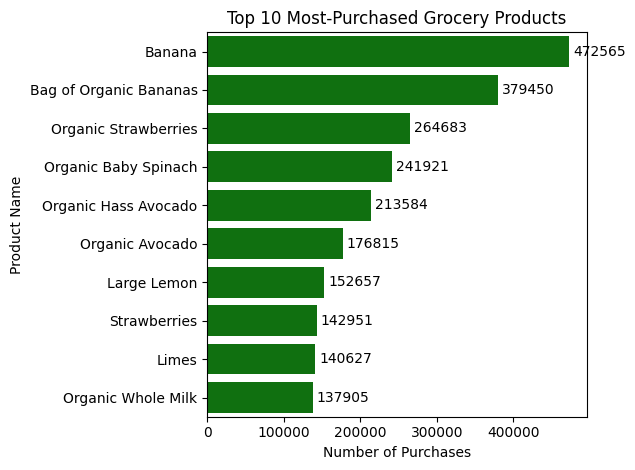

In [37]:
ax=sns.barplot(data=top_products, x="purchases", y="product_name", color="green")
ax.bar_label(ax.containers[0], padding=3)
plt.title("Top 10 Most-Purchased Grocery Products")
plt.xlabel("Number of Purchases")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

In [20]:
reorder_products = db.query("""
SELECT
    p.product_name,
    COUNT(*) AS total_purchases,
    ROUND(AVG(op.reordered) * 100, 2) AS reorder_rate
FROM order_products_prior op
JOIN products p
ON op.product_id = p.product_id
GROUP BY p.product_name
HAVING COUNT(*) >= 1000
ORDER BY reorder_rate DESC
LIMIT 10
""").to_df()

display(reorder_products)

,product_name,total_purchases,reorder_rate
0,Half And Half Ultra Pasteurized,2921,86.17
1,Whole Organic Omega 3 Milk,9108,86.02
2,Organic Lactose Free Whole Milk,8477,85.90
3,Organic Homogenized Whole Milk,3970,85.77
4,Ultra-Purified Water,1489,85.76
5,"Milk, Organic, Vitamin D",20198,85.43
6,Organic Reduced Fat Milk,35663,85.07
7,Goat Milk,5185,85.00
8,Banana,472565,84.35
9,Organic Whole Milk,9842,84.12


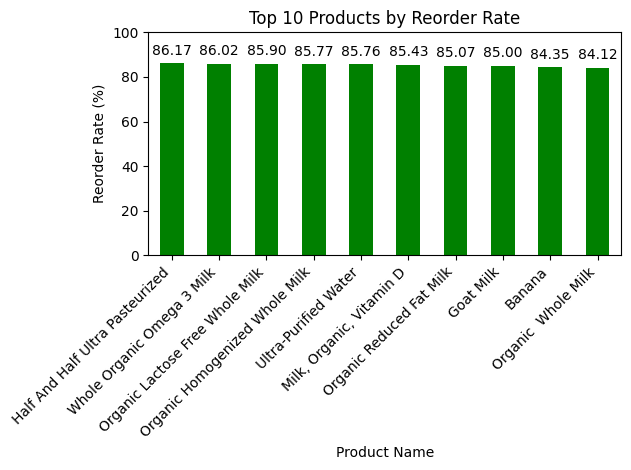

In [34]:
ay=reorder_products.plot(x="product_name", y="reorder_rate",kind="bar",legend=False,color="green")
ay.bar_label(ay.containers[0], padding=4, fmt="%.2f")
plt.title("Top 10 Products by Reorder Rate")
plt.xlabel("Product Name")
plt.ylabel("Reorder Rate (%)")
ay.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [39]:
orders_by_day = db.query("""
SELECT
    order_dow,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_dow
ORDER BY order_dow
""").to_df()

display(orders_by_day)

,order_dow,total_orders
0,0,600905
1,1,587478
2,2,467260
3,3,436972
4,4,426339
5,5,453368
6,6,448761


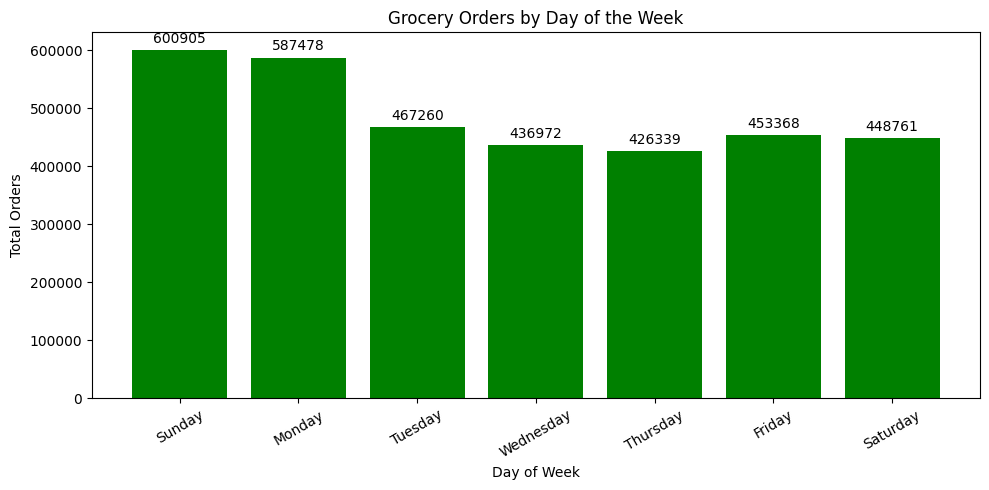

In [46]:
import matplotlib.pyplot as plt
day_names = {
    0: "Sunday",
    1: "Monday",
    2: "Tuesday",
    3: "Wednesday",
    4: "Thursday",
    5: "Friday",
    6: "Saturday"
}

orders_by_day["day_name"] = orders_by_day["order_dow"].map(day_names)
plt.figure(figsize=(10, 5))
bars = plt.bar(orders_by_day["day_name"],orders_by_day["total_orders"],color="green")
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Grocery Orders by Day of the Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Orders")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [47]:
orders_by_hour = db.query("""
SELECT
    order_hour_of_day,
    COUNT(*) AS total_orders
FROM orders
GROUP BY order_hour_of_day
ORDER BY order_hour_of_day
""").to_df()

display(orders_by_hour)

,order_hour_of_day,total_orders
0,0,22758
1,1,12398
2,2,7539
3,3,5474
4,4,5527
5,5,9569
6,6,30529
7,7,91868
8,8,178201
9,9,257812


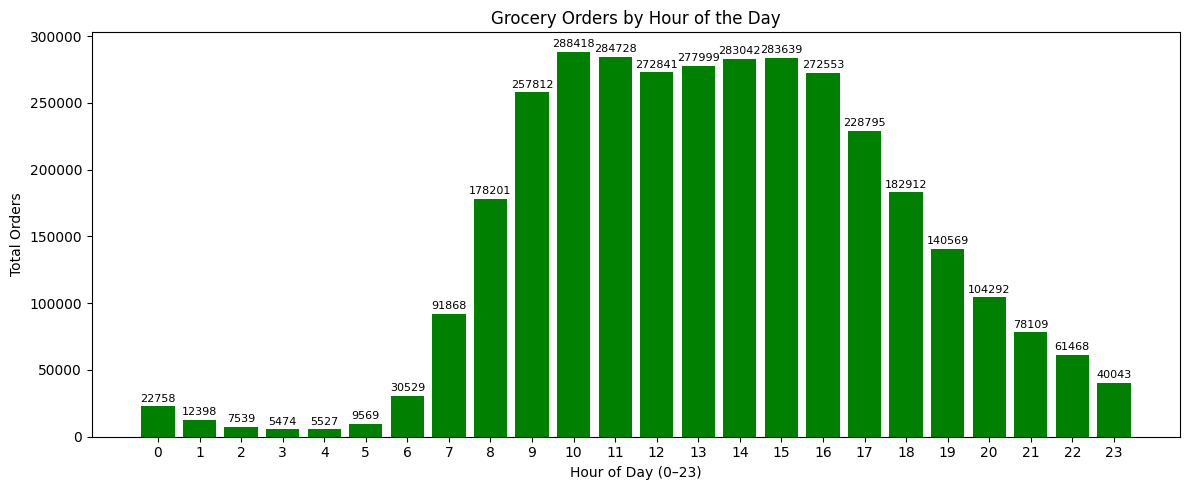

In [55]:
plt.figure(figsize=(12, 5))
bars = plt.bar(orders_by_hour["order_hour_of_day"],orders_by_hour["total_orders"],color="green")
plt.bar_label(bars, fmt="%.0f", padding=2, fontsize=8)
plt.title("Grocery Orders by Hour of the Day")
plt.xlabel("Hour of Day (0–23)")
plt.ylabel("Total Orders")
plt.xticks(range(24))
plt.tight_layout()
plt.show()

In [61]:
[name for name, obj in globals().copy().items()
 if isinstance(obj, pd.DataFrame)]

['_',
 '_4',
 'metrics',
 'top_products',
 'reorder_products',
 'plot_data',
 'orders_by_day',
 'orders_by_hour',
 'kpi']

In [62]:
import os
os.makedirs("grocery_outputs", exist_ok=True)
output_tables = {
    "metrics": metrics,
    "top_products": top_products,
    "reorder_products": reorder_products,
    "orders_by_day": orders_by_day,
    "orders_by_hour": orders_by_hour,
    "kpi": kpi}
for name, df in output_tables.items():
    df.to_csv(f"grocery_outputs/{name}.csv", index=False)
    print(f"Exported: {name}.csv — {len(df)} rows")

Exported: metrics.csv — 1 rows
Exported: top_products.csv — 10 rows
Exported: reorder_products.csv — 10 rows
Exported: orders_by_day.csv — 7 rows
Exported: orders_by_hour.csv — 24 rows
Exported: kpi.csv — 1 rows


In [63]:
customer_metrics = db.query("""
WITH customer_orders AS (
    SELECT
        user_id,
        COUNT(*) AS total_orders,
        AVG(days_since_prior_order) AS avg_days_between_orders
    FROM orders
    GROUP BY user_id
),
customer_products AS (
    SELECT
        o.user_id,
        COUNT(*) AS total_products_purchased,
        ROUND(AVG(op.reordered) * 100, 2) AS reorder_rate
    FROM order_products_prior op
    JOIN orders o
        ON op.order_id = o.order_id
    GROUP BY o.user_id
)
SELECT
    co.user_id,
    co.total_orders,
    ROUND(co.avg_days_between_orders, 2)
        AS avg_days_between_orders,
    COALESCE(cp.total_products_purchased, 0)
        AS total_products_purchased,
    COALESCE(cp.reorder_rate, 0)
        AS reorder_rate
FROM customer_orders co
LEFT JOIN customer_products cp
    ON co.user_id = cp.user_id
ORDER BY co.user_id
""").to_df()

display(customer_metrics.head(10))


,user_id,total_orders,avg_days_between_orders,total_products_purchased,reorder_rate
0,1,11,19.00,59,69.49
1,2,15,16.29,195,47.69
2,3,13,12.00,88,62.50
3,4,6,17.00,18,5.56
4,5,5,11.50,37,37.84
5,6,4,13.33,14,14.29
6,7,21,10.45,206,66.99
7,8,4,23.33,49,26.53
8,9,4,22.00,76,23.68
9,10,6,21.80,143,34.27


In [65]:
print("Column names:")
print(customer_metrics.columns.tolist())
print("\nDataset shape:")
print(customer_metrics.shape)
print("\nSummary statistics:")
display(customer_metrics.describe().round(2))

Column names:
['user_id', 'total_orders', 'avg_days_between_orders', 'total_products_purchased', 'reorder_rate']

Dataset shape:
(206209, 5)

Summary statistics:


,user_id,total_orders,avg_days_between_orders,total_products_purchased,reorder_rate
count,206209.00,206209.00,206209.00,206209.00,206209.00
mean,103105.00,16.59,15.45,157.29,43.22
std,59527.56,16.65,6.92,204.21,21.21
min,1.00,4.00,0.00,3.00,0.00
25%,51553.00,6.00,9.81,39.00,26.79
50%,103105.00,10.00,15.00,83.00,42.86
75%,154657.00,20.00,20.63,188.00,59.57
max,206209.00,100.00,30.00,3725.00,98.95


In [67]:
def segment_customer(row):
    if row["total_orders"] >= 20 and row["reorder_rate"] >= 50:
        return "Loyal Customers"
    elif row["total_orders"] >= 10 and row["reorder_rate"] >= 40:
        return "Regular Customers"
    elif row["total_orders"] < 10 and row["reorder_rate"] < 30:
        return "Occasional / Low-Reorder Customers"
    else:
        return "Developing Customers"
customer_metrics["customer_segment"] = customer_metrics.apply(segment_customer, axis=1)
segment_summary = (customer_metrics.groupby("customer_segment").agg(customer_count=("user_id", "nunique"),
avg_orders=("total_orders", "mean"),avg_reorder_rate=("reorder_rate", "mean"),avg_products_purchased=("total_products_purchased", "mean"))
.round(2).reset_index())
segment_summary["customer_percentage"] = (segment_summary["customer_count"]/ customer_metrics["user_id"].nunique()* 100).round(2)
display(segment_summary)

,customer_segment,customer_count,avg_orders,avg_reorder_rate,avg_products_purchased,customer_percentage
0,Developing Customers,64054,9.25,39.10,76.40,31.06
1,Loyal Customers,45554,40.40,68.60,411.57,22.09
2,Occasional / Low-Reorder Customers,52509,5.49,17.02,41.21,25.46
3,Regular Customers,44092,15.88,54.20,150.32,21.38


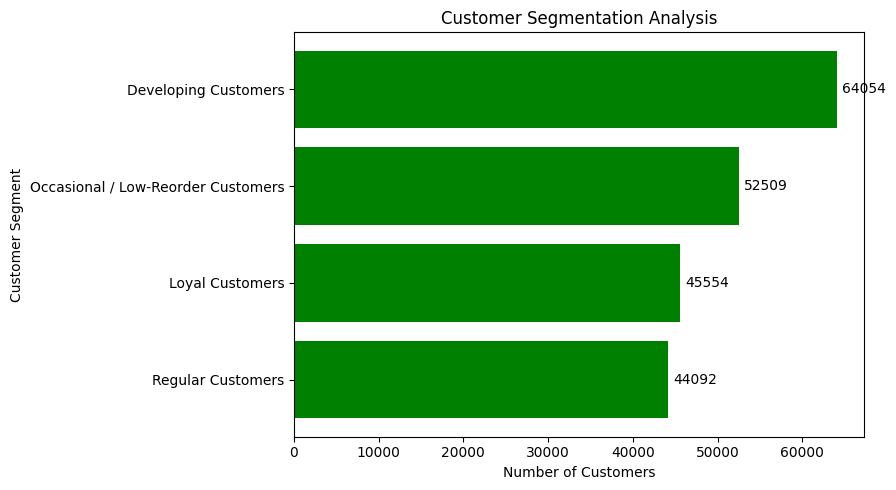

In [70]:
#Customer segmentation chart
chart_data = segment_summary.sort_values("customer_count", ascending=True)
plt.figure(figsize=(9, 5))
bars = plt.barh(chart_data["customer_segment"],chart_data["customer_count"],color="green")
plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Customer Segmentation Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Customer Segment")
plt.tight_layout()
plt.show()

In [71]:
customer_metrics.to_csv("grocery_outputs/customer_segmentation.csv",index=False)
segment_summary.to_csv("grocery_outputs/customer_segment_summary.csv",index=False)
print("Customer segmentation files exported successfully.")

Customer segmentation files exported successfully.


In [73]:
#frequently purchased product pairs
product_pairs = db.query("""SELECT
p1.product_name AS product_1,p2.product_name AS product_2,COUNT(*) AS times_bought_together
FROM order_products_prior a
JOIN order_products_prior b
    ON a.order_id = b.order_id
    AND a.product_id < b.product_id
JOIN products p1
    ON a.product_id = p1.product_id
JOIN products p2
    ON b.product_id = p2.product_id
GROUP BY p1.product_name, p2.product_name
HAVING COUNT(*) >= 100
ORDER BY times_bought_together DESC
LIMIT 20
""").to_df()
display(product_pairs)

,product_1,product_2,times_bought_together
0,Bag of Organic Bananas,Organic Hass Avocado,62341
1,Bag of Organic Bananas,Organic Strawberries,61628
2,Organic Strawberries,Banana,56156
3,Banana,Organic Avocado,53395
4,Organic Baby Spinach,Banana,51395
5,Bag of Organic Bananas,Organic Baby Spinach,50372
6,Strawberries,Banana,41232
7,Banana,Large Lemon,40880
8,Organic Strawberries,Organic Hass Avocado,40794
9,Bag of Organic Bananas,Organic Raspberries,40503


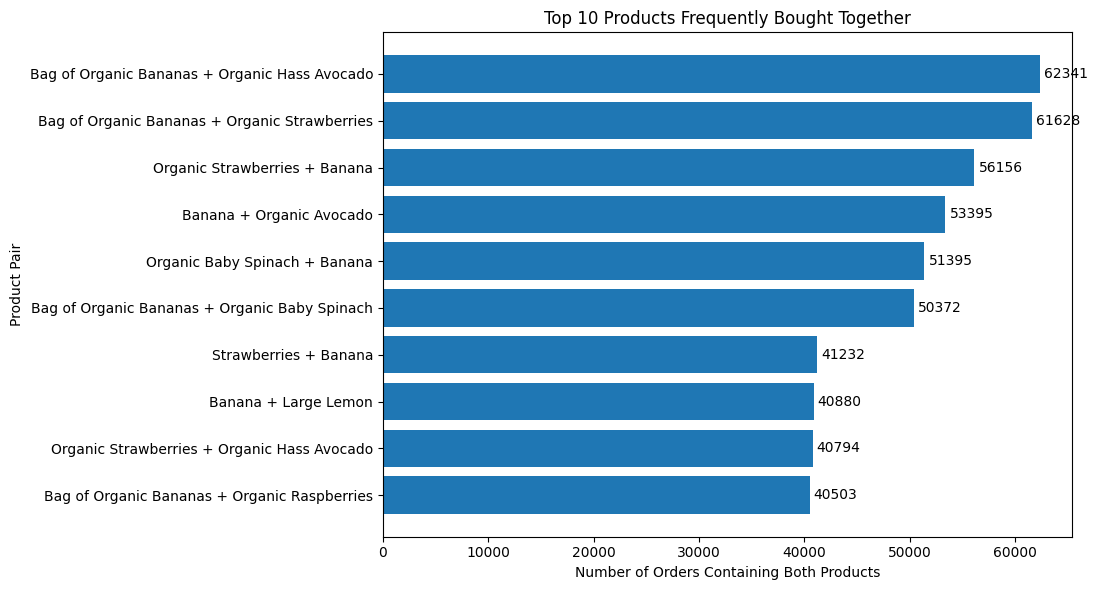

In [74]:
top_pairs = product_pairs.head(10).copy()
top_pairs["pair"] = (top_pairs["product_1"] + " + " + top_pairs["product_2"])
top_pairs = top_pairs.sort_values("times_bought_together")
plt.figure(figsize=(11, 6))
bars = plt.barh(top_pairs["pair"],top_pairs["times_bought_together"])
plt.bar_label(bars, fmt="%.0f", padding=3)
plt.title("Top 10 Products Frequently Bought Together")
plt.xlabel("Number of Orders Containing Both Products")
plt.ylabel("Product Pair")
plt.tight_layout()
plt.show()


In [75]:
product_pairs.to_csv("grocery_outputs/cross_sell_product_pairs.csv",index=False)
print("Cross-sell results exported successfully.")

Cross-sell results exported successfully.


In [77]:
retention = db.query("""
WITH customer_orders AS (SELECT user_id,COUNT(*) AS total_orders,MAX(order_number) AS last_order_number,
MAX(days_since_prior_order) AS longest_order_gap
FROM orders GROUP BY user_id)
SELECT
    CASE
        WHEN total_orders = 1 THEN 'One Recorded Order'
        WHEN total_orders BETWEEN 2 AND 5 THEN '2-5 Orders'
        WHEN total_orders BETWEEN 6 AND 10 THEN '6-10 Orders'
        ELSE '11+ Orders'
    END AS order_frequency_group,
    COUNT(*) AS customer_count,ROUND(AVG(total_orders), 2) AS avg_orders_per_customer
FROM customer_orders
GROUP BY order_frequency_group
ORDER BY customer_count DESC
""").to_df()
display(retention)

,order_frequency_group,customer_count,avg_orders_per_customer
0,11+ Orders,101696,27.12
1,6-10 Orders,60937,7.71
2,2-5 Orders,43576,4.45


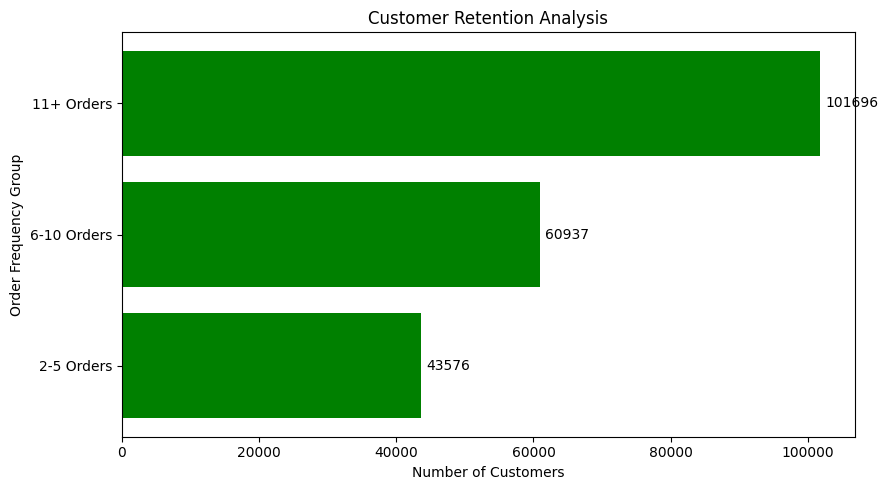

In [79]:
#Customer Retention Analysis
retention_chart = retention.sort_values("customer_count", ascending=True)
plt.figure(figsize=(9, 5))
bars = plt.barh(retention_chart["order_frequency_group"],retention_chart["customer_count"],color="green")
plt.bar_label(bars, fmt="%.0f", padding=4)
plt.title("Customer Retention Analysis")
plt.xlabel("Number of Customers")
plt.ylabel("Order Frequency Group")
plt.tight_layout()
plt.show()

In [80]:
retention.to_csv("grocery_outputs/customer_retention.csv", index=False)
print("Customer retention analysis exported successfully!")

Customer retention analysis exported successfully!


In [81]:

for table in ["orders", "order_products_prior", "products"]:
    print(f"\n--- {table} ---")
    display(db.query(f"DESCRIBE {table}").to_df())



--- orders ---


,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,user_id,BIGINT,YES,None,None,None
2,eval_set,VARCHAR,YES,None,None,None
3,order_number,BIGINT,YES,None,None,None
4,order_dow,BIGINT,YES,None,None,None
5,order_hour_of_day,INTEGER,YES,None,None,None
6,days_since_prior_order,DOUBLE,YES,None,None,None



--- order_products_prior ---


,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,product_id,BIGINT,YES,None,None,None
2,add_to_cart_order,BIGINT,YES,None,None,None
3,reordered,BIGINT,YES,None,None,None



--- products ---


,column_name,column_type,null,key,default,extra
0,product_id,BIGINT,YES,None,None,None
1,product_name,VARCHAR,YES,None,None,None
2,aisle_id,BIGINT,YES,None,None,None
3,department_id,BIGINT,YES,None,None,None


In [82]:
display(db.query("""
SELECT
    eval_set,
    COUNT(*) AS total_orders,
    COUNT(DISTINCT user_id) AS total_customers
FROM orders
GROUP BY eval_set
ORDER BY eval_set
""").to_df())


,eval_set,total_orders,total_customers
0,prior,3214874,206209
1,test,75000,75000
2,train,131209,131209


In [83]:
display(db.query("""
SHOW TABLES
""").to_df())

,name
0,aisles
1,departments
2,order_products_prior
3,order_products_train
4,order_summary
5,orders
6,products


In [84]:

display(db.query("DESCRIBE order_products_train").to_df())

display(db.query("""
SELECT
    COUNT(*) AS total_product_rows,
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT product_id) AS unique_products
FROM order_products_train
""").to_df())

display(db.query("""
SELECT *
FROM order_products_train
LIMIT 5
""").to_df())


,column_name,column_type,null,key,default,extra
0,order_id,BIGINT,YES,None,None,None
1,product_id,BIGINT,YES,None,None,None
2,add_to_cart_order,BIGINT,YES,None,None,None
3,reordered,BIGINT,YES,None,None,None


,total_product_rows,total_orders,unique_products
0,1384617,131209,39123


,order_id,product_id,add_to_cart_order,reordered
0,1,49302,1,1
1,1,11109,2,1
2,1,10246,3,0
3,1,49683,4,0
4,1,43633,5,1


In [86]:
%pip install scikit-learn

   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   - -------------------------------------- 0.3/8.4 MB ? eta -:--:--
   -- ------------------------------------- 0.5/8.4 MB 260.1 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/8.4 MB 260.1 kB/s eta 0:00:31
   -- ------------------------------------- 0.5/8.4 MB 260.1 kB/s eta 0:00:31
   -- -


[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [87]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.9.1


In [88]:
reorder_data = db.query("""WITH user_orders AS (
SELECT user_id,MAX(order_number) AS total_prior_orders
FROM orders WHERE eval_set = 'prior' GROUP BY user_id),
product_history AS (SELECT
o.user_id,op.product_id,COUNT(*) AS purchase_count,AVG(op.reordered) AS reorder_rate,
MAX(o.order_number) AS last_order_number 
FROM orders o
JOIN order_products_prior op 
  ON o.order_id = op.order_id
WHERE o.eval_set = 'prior' 
GROUP BY o.user_id, op.product_id),
train_products AS (SELECT DISTINCT o.user_id,tp.product_id
FROM orders o
JOIN order_products_train tp
   ON o.order_id = tp.order_id
WHERE o.eval_set = 'train')
SELECT h.purchase_count,h.reorder_rate,u.total_prior_orders,
u.total_prior_orders - h.last_order_number AS orders_since_last_purchase,
    CASE
        WHEN t.product_id IS NOT NULL THEN 1
        ELSE 0
    END AS reordered_next
FROM product_history h
JOIN user_orders u
    ON h.user_id = u.user_id
LEFT JOIN train_products t
    ON h.user_id = t.user_id
    AND h.product_id = t.product_id
USING SAMPLE 100000 ROWS
""").to_df()

print("Dataset shape:", reorder_data.shape)
display(reorder_data.head())

Dataset shape: (100000, 5)


,purchase_count,reorder_rate,total_prior_orders,orders_since_last_purchase,reordered_next
0,1,0.0000,7,5,0
1,1,0.0000,9,5,0
2,1,0.0000,22,20,0
3,16,0.9375,43,0,0
4,1,0.0000,26,6,0


In [89]:
print("Target distribution:")
display(reorder_data["reordered_next"].value_counts().rename(index={0: "Not reordered", 1: "Reordered"})
.to_frame("Record count"))
print("\nTarget percentages:")
display((reorder_data["reordered_next"]
     .value_counts(normalize=True) * 100)
    .rename(index={0: "Not reordered", 1: "Reordered"})
    .round(2)
    .to_frame("Percentage")
)

Target distribution:


,Record count
reordered_next,
Not reordered,93792
Reordered,6208



Target percentages:


,Percentage
reordered_next,
Not reordered,93.79
Reordered,6.21


In [90]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (classification_report,confusion_matrix,accuracy_score)

# Features and target
X = reorder_data[["purchase_count","reorder_rate","total_prior_orders","orders_since_last_purchase"]]
y = reorder_data["reordered_next"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y,test_size=0.2,random_state=42,stratify=y)

# Train the model
model = DecisionTreeClassifier(max_depth=5,class_weight="balanced",random_state=42)
model.fit(X_train, y_train)

# Make predictions
y_pred = model.predict(X_test)

# Evaluate the model
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))

print("\nClassification Report:")
print(classification_report(y_test,y_pred,target_names=["Not Reordered", "Reordered"],zero_division=0))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.7198

Classification Report:
               precision    recall  f1-score   support

Not Reordered       0.97      0.72      0.83     18758
    Reordered       0.14      0.71      0.24      1242

     accuracy                           0.72     20000
    macro avg       0.56      0.72      0.53     20000
 weighted avg       0.92      0.72      0.79     20000

Confusion Matrix:
[[13511  5247]
 [  358   884]]


,Feature,Importance
3,orders_since_last_purchase,0.738818
1,reorder_rate,0.181579
0,purchase_count,0.051987
2,total_prior_orders,0.027615


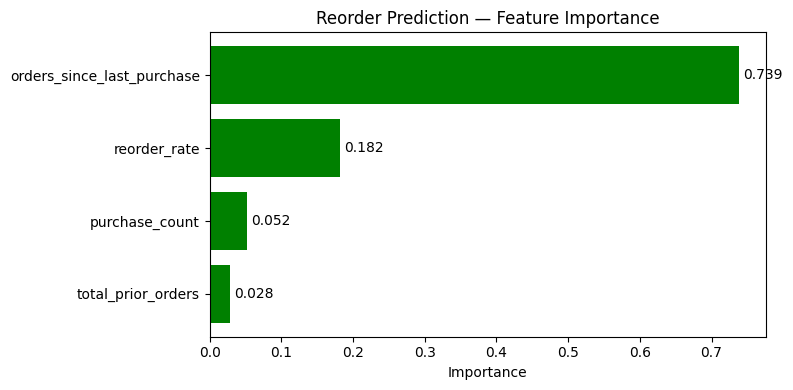

In [92]:
feature_importance = pd.DataFrame({"Feature": X.columns,"Importance": model.feature_importances_
}).sort_values("Importance", ascending=True)

display(feature_importance.sort_values("Importance", ascending=False))

plt.figure(figsize=(8, 4))
bars = plt.barh(feature_importance["Feature"],feature_importance["Importance"],color="green")
plt.bar_label(bars, fmt="%.3f", padding=3)
plt.title("Reorder Prediction — Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

In [93]:
import os
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score
os.makedirs("grocery_outputs", exist_ok=True)

# Save feature importance
feature_importance.sort_values("Importance", ascending=False).to_csv("grocery_outputs/reorder_feature_importance.csv",index=False)

# Save evaluation metrics
model_results = pd.DataFrame([{"accuracy": accuracy_score(y_test, y_pred),"reorder_precision": precision_score(y_test, y_pred, zero_division=0),
"reorder_recall": recall_score(y_test, y_pred, zero_division=0),"reorder_f1_score": f1_score(y_test, y_pred, zero_division=0)}])

model_results.to_csv("grocery_outputs/reorder_model_evaluation.csv",index=False)
print("Model results saved successfully!")
display(model_results.round(3))

Model results saved successfully!


,accuracy,reorder_precision,reorder_recall,reorder_f1_score
0,0.72,0.144,0.712,0.24


In [94]:
import os
for file in sorted(os.listdir("grocery_outputs")):
    print(file)

cross_sell_product_pairs.csv
customer_retention.csv
customer_segment_summary.csv
customer_segmentation.csv
kpi.csv
metrics.csv
orders_by_day.csv
orders_by_hour.csv
reorder_feature_importance.csv
reorder_model_evaluation.csv
reorder_products.csv
top_products.csv
